
# E03 — RT-DETR-L Baseline

## Objective
Train and evaluate a Transformer-based bird detector.

## Model
RT-DETR-L (COCO pretrained)

## Dataset
Beach Bird Detection Dataset v1.0

## Experiment Plan
1. Inspect architecture
2. Verify configuration
3. Smoke training
4. Full baseline training
5. Visualize training metrics
6. Compare with YOLO11n

## Evaluation
- Precision / Recall
- mAP@0.5 / mAP@0.5:0.95
- Training and inference time
- Failure analysis


In [2]:

from pathlib import Path
import pandas as pd
import yaml
import torch
from ultralytics import RTDETR

# Project directory
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

# Load configuration
config_path = ROOT / "configs/rtdetr_baseline.yaml"

with open(config_path) as f:
    config = yaml.safe_load(f)

# Load pretrained RT-DETR
model = RTDETR(config["model"])

# Print model summary
model.info(imgsz=config["imgsz"])

# Inspect network modules
layers = []

for layer in model.model.model:
    layers.append({
        "Index": layer.i,
        "From": str(layer.f),
        "Module": type(layer).__name__,
        "Parameters": sum(
            p.numel() for p in layer.parameters()
        )
    })

architecture_df = pd.DataFrame(layers)
display(architecture_df)

print("Total parameters:",
      sum(p.numel() for p in model.model.parameters()))

print("Pretrained classes:", model.model.model[-1].nc)
print("MPS available:", torch.backends.mps.is_available())


rt-detr-l summary: 449 layers, 32,970,476 parameters, 0 gradients, 110.2 GFLOPs


,Index,From,Module,Parameters
0,0,-1,HGStem,25248
1,1,-1,HGBlock,155072
2,2,-1,DWConv,1408
3,3,-1,HGBlock,839296
4,4,-1,DWConv,5632
5,5,-1,HGBlock,1695360
6,6,-1,HGBlock,2055808
7,7,-1,HGBlock,2055808
8,8,-1,DWConv,11264
9,9,-1,HGBlock,6708480


Total parameters: 32970476
Pretrained classes: 80
MPS available: True


In [3]:

import time
from ultralytics import RTDETR

# 1. Copy baseline configuration
smoke_config = config.copy()

model_name = smoke_config.pop("model")

smoke_config["data"] = str(ROOT / smoke_config["data"])
smoke_config["project"] = str(ROOT / smoke_config["project"])

# 2. Override parameters for smoke testing
smoke_config.update({
    "epochs": 1,
    "fraction": 0.05,
    "batch": 2,
    "amp": False,
    "plots": False,
    "name": "rtdetr_l_smoke_v1",
})

# 3. Load pretrained model
smoke_model = RTDETR(model_name)

# 4. Run smoke training
start = time.perf_counter()

smoke_model.train(**smoke_config)

elapsed = time.perf_counter() - start

print("\n===== RT-DETR Smoke Test =====")
print(f"Elapsed time: {elapsed:.2f} seconds")
print("Output:", smoke_model.trainer.save_dir)


New https://pypi.org/project/ultralytics/8.4.201 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.199 🚀 Python-3.11.16 torch-2.15.0 MPS (Apple M4 Pro)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/luzhang/COMP9517/comp9517-bird-detection/data/beach_bird.yaml, degrees=0.0, deterministic=False, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=0.05, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train

In [4]:

from ultralytics import RTDETR
from pathlib import Path
import pandas as pd
import time

# Load configuration
profile_config = config.copy()
model_name = profile_config.pop("model")

profile_config["data"] = str(ROOT / profile_config["data"])
profile_config["project"] = str(ROOT / profile_config["project"])

# Full dataset, 5 epochs
profile_config.update({
    "epochs": 5,
    "fraction": 1.0,
    "batch": 2,
    "amp": False,
    "plots": True,
    "name": "rtdetr_l_profile5_v1",
    "exist_ok": False,
})

# Train
profile_model = RTDETR(model_name)

start = time.perf_counter()
profile_model.train(**profile_config)
elapsed = time.perf_counter() - start

# Read training logs
run_dir = Path(profile_model.trainer.save_dir)
df = pd.read_csv(run_dir / "results.csv")
df.columns = df.columns.str.strip()

# Calculate per-epoch elapsed time
df["epoch_time"] = df["time"].diff().fillna(df["time"])

display(df[["epoch", "time", "epoch_time"]])

print(f"\nTotal wall time: {elapsed:.1f} seconds")
print(f"Average epoch time: {df['epoch_time'].mean():.1f} seconds")
print(f"Average last 3 epochs: {df['epoch_time'].tail(3).mean():.1f} seconds")

# Rough estimate assuming similar epoch times
estimated_total = (
    elapsed + 45 * df["epoch_time"].tail(3).mean()
)

print(f"Estimated 50-epoch total: {estimated_total/3600:.2f} hours")
print("Results:", run_dir)


New https://pypi.org/project/ultralytics/8.4.201 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.199 🚀 Python-3.11.16 torch-2.15.0 MPS (Apple M4 Pro)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/luzhang/COMP9517/comp9517-bird-detection/data/beach_bird.yaml, degrees=0.0, deterministic=False, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train,

,epoch,time,epoch_time
0,1,247.483,247.483
1,2,491.813,244.330
2,3,736.249,244.436
3,4,978.308,242.059
4,5,1220.190,241.882



Total wall time: 1236.6 seconds
Average epoch time: 244.0 seconds
Average last 3 epochs: 242.8 seconds
Estimated 50-epoch total: 3.38 hours
Results: /Users/luzhang/COMP9517/comp9517-bird-detection/runs/train/rtdetr_l_profile5_v1


Available metrics:
['epoch', 'time', 'train/giou_loss', 'train/cls_loss', 'train/l1_loss', 'metrics/precision(B)', 'metrics/recall(B)', 'metrics/mAP50(B)', 'metrics/mAP50-95(B)', 'val/giou_loss', 'val/cls_loss', 'val/l1_loss', 'lr/pg0', 'lr/pg1', 'lr/pg2']


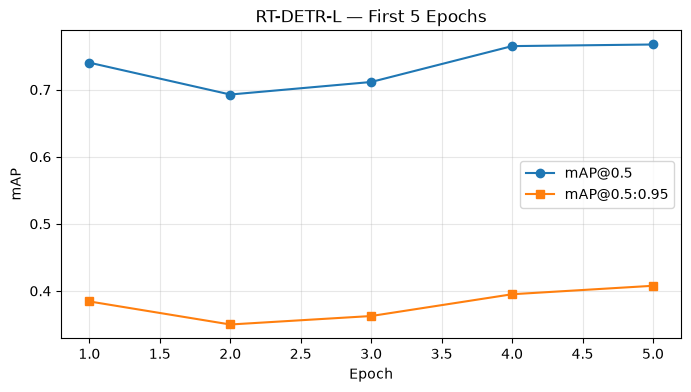

In [5]:

import pandas as pd
import matplotlib.pyplot as plt

# Read the 5-epoch profiling results
df = pd.read_csv(
    ROOT / "runs/train/rtdetr_l_profile5_v1/results.csv"
)
df.columns = df.columns.str.strip()

# Show all recorded metrics
print("Available metrics:")
print(df.columns.tolist())

# Visualize validation performance
plt.figure(figsize=(8, 4))

plt.plot(
    df["epoch"],
    df["metrics/mAP50(B)"],
    marker="o",
    label="mAP@0.5"
)

plt.plot(
    df["epoch"],
    df["metrics/mAP50-95(B)"],
    marker="s",
    label="mAP@0.5:0.95"
)

plt.xlabel("Epoch")
plt.ylabel("mAP")
plt.title("RT-DETR-L — First 5 Epochs")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [1]:

from ultralytics import RTDETR
from pathlib import Path
from datetime import datetime
import yaml
import json
import time
import platform
import torch
import ultralytics

# Load experiment configuration
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

with open(ROOT / "configs/rtdetr_baseline.yaml") as f:
    train_config = yaml.safe_load(f)

model_name = train_config.pop("model")

train_config["data"] = str(ROOT / train_config["data"])
train_config["project"] = str(ROOT / train_config["project"])

# Disable mixed precision on MPS
train_config["amp"] = False
train_config["name"] = "rtdetr_l_baseline_v1"

# Load COCO pretrained weights
model = RTDETR(model_name)

# Start experiment
started_at = datetime.now().astimezone().isoformat()
start = time.perf_counter()

model.train(**train_config)

elapsed = time.perf_counter() - start
run_dir = Path(model.trainer.save_dir)

# Save experiment metadata
metadata = {
    "experiment": "E03 RT-DETR-L Baseline",
    "started_at": started_at,
    "wall_time_seconds": round(elapsed, 2),
    "model": model_name,
    "pytorch_version": torch.__version__,
    "ultralytics_version": ultralytics.__version__,
    "platform": platform.platform(),
    "configuration": train_config,
}

with open(run_dir / "experiment_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("\n===== E03 Training Completed =====")
print(f"Wall time: {elapsed / 3600:.2f} hours")
print("Results:", run_dir)


New https://pypi.org/project/ultralytics/8.4.201 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.199 🚀 Python-3.11.16 torch-2.15.0 MPS (Apple M4 Pro)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/Users/luzhang/COMP9517/comp9517-bird-detection/data/beach_bird.yaml, degrees=0.0, deterministic=False, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train

In [3]:

import yaml

args_path = (
    ROOT / "runs/train/rtdetr_l_baseline_v1/args.yaml"
)

args = yaml.safe_load(args_path.read_text())

for key in [
    "optimizer",
    "lr0",
    "lrf",
    "warmup_epochs",
    "weight_decay",
    "patience",
    "batch",
    "epochs",
]:
    print(f"{key}: {args.get(key)}")


NameError: name 'ROOT' is not defined

In [3]:

import yaml

for run_name in [
    "rtdetr_l_profile5_v1",
    "rtdetr_l_baseline_v1"
]:
    args_path = ROOT / "runs/train" / run_name / "args.yaml"
    args = yaml.safe_load(args_path.read_text())

    print(f"\n{run_name}")
    print("Epochs:", args["epochs"])
    print("Mosaic:", args.get("mosaic"))
    print("Close Mosaic:", args.get("close_mosaic"))
    print("Optimizer:", args.get("optimizer"))
    print("Warmup Epochs:", args.get("warmup_epochs"))



rtdetr_l_profile5_v1
Epochs: 5
Mosaic: 1.0
Close Mosaic: 10
Optimizer: auto
Warmup Epochs: 3.0

rtdetr_l_baseline_v1
Epochs: 50
Mosaic: 1.0
Close Mosaic: 10
Optimizer: auto
Warmup Epochs: 3.0


In [3]:

from ultralytics import RTDETR
from pathlib import Path
import yaml
import time
import json

# Project root
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

# Load E03-B configuration
config_path = ROOT / "configs/rtdetr_stable_v1.yaml"

with open(config_path) as f:
    stable_config = yaml.safe_load(f)

model_name = stable_config.pop("model")

stable_config["data"] = str(ROOT / stable_config["data"])
stable_config["project"] = str(ROOT / stable_config["project"])

# Verify key settings
for key in [
    "epochs", "mosaic", "close_mosaic",
    "patience", "optimizer", "lr0", "lrf"
]:
    print(f"{key}: {stable_config.get(key)}")

# Load pretrained RT-DETR-L
stable_model = RTDETR(model_name)

# Start training
start = time.perf_counter()

stable_model.train(**stable_config)

elapsed = time.perf_counter() - start
run_dir = Path(stable_model.trainer.save_dir)

# Save additional experiment metadata
metadata = {
    "experiment": "E03-B RT-DETR Stable Fine-tuning",
    "model": model_name,
    "wall_time_seconds": round(elapsed, 2),
    "configuration": stable_config,
}

with open(run_dir / "experiment_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2)

print("\n===== E03-B Completed =====")
print(f"Training time: {elapsed / 3600:.2f} hours")
print("Output:", run_dir)


epochs: 35
mosaic: 0.5
close_mosaic: 25
patience: 0
optimizer: AdamW
lr0: 0.0005
lrf: 0.1
New https://pypi.org/project/ultralytics/8.4.201 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.199 🚀 Python-3.11.16 torch-2.15.0 MPS (Apple M4 Pro)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=25, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/Users/luzhang/COMP9517/comp9517-bird-detection/data/beach_bird.yaml, degrees=0.0, deterministic=False, device=mps, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=35, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1

In [4]:

from ultralytics import RTDETR

best_path = (
    ROOT / "runs/train/rtdetr_l_stable_v1"
    / "weights/best.pt"
)

best_model = RTDETR(str(best_path))

metrics = best_model.val(
    data=str(ROOT / "data/beach_bird.yaml"),
    split="val",
    imgsz=640,
    batch=2,
    device="mps",
    plots=False
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP@0.5:", metrics.box.map50)
print("mAP@0.5:0.95:", metrics.box.map)


Ultralytics 8.4.199 🚀 Python-3.11.16 torch-2.15.0 MPS (Apple M4 Pro)
rt-detr-l summary (fused): 315 layers, 31,985,795 parameters, 0 gradients, 105.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 250.1±134.9 MB/s, size: 95.0 KB)
val: Scanning /Users/luzhang/COMP9517/comp9517-bird-detection/data/beach_bird/Beach Bird Detection Dataset v1.0/labels/val.cache... 291 images, 33 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 291/291 305.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 146/146 13.3it/s 11.0s0.1s
                   all        291       1843      0.165      0.485      0.155     0.0649
Speed: 0.6ms preprocess, 27.6ms inference, 0.0ms loss, 4.2ms postprocess per image
Precision: 0.16451053279821964
Recall: 0.48507867607162236
mAP@0.5: 0.15472703231220808
mAP@0.5:0.95: 0.06493782158207725


In [5]:

from pathlib import Path
import pandas as pd
from datetime import datetime

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

train_root = ROOT / "runs/train"

for run in sorted(train_root.glob("rtdetr_l_stable_v1*")):
    csv_path = run / "results.csv"
    best_path = run / "weights/best.pt"

    print(f"\nExperiment: {run.name}")
    print("Best weights:", best_path)
    print("Weights exist:", best_path.exists())

    if best_path.exists():
        print(
            "Weights modified:",
            datetime.fromtimestamp(
                best_path.stat().st_mtime
            )
        )

    if csv_path.exists():
        df = pd.read_csv(csv_path)
        df.columns = df.columns.str.strip()

        print("Completed Epochs:", int(df["epoch"].iloc[-1]))
        print(
            "Best mAP50:",
            round(df["metrics/mAP50(B)"].max(), 4)
        )
        print(
            "Best mAP50-95:",
            round(df["metrics/mAP50-95(B)"].max(), 4)
        )



Experiment: rtdetr_l_stable_v1
Best weights: /Users/luzhang/COMP9517/comp9517-bird-detection/runs/train/rtdetr_l_stable_v1/weights/best.pt
Weights exist: True
Weights modified: 2026-11-04 06:54:55.568066
Completed Epochs: 1
Best mAP50: 0.1547
Best mAP50-95: 0.0649

Experiment: rtdetr_l_stable_v1-2
Best weights: /Users/luzhang/COMP9517/comp9517-bird-detection/runs/train/rtdetr_l_stable_v1-2/weights/best.pt
Weights exist: True
Weights modified: 2026-11-04 09:39:15.485717
Completed Epochs: 35
Best mAP50: 0.8974
Best mAP50-95: 0.5082


In [6]:

from ultralytics import RTDETR
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

# Correct checkpoint: 35-epoch experiment
best_path = (
    ROOT / "runs/train/rtdetr_l_stable_v1-2"
    / "weights/best.pt"
)

print("Loading:", best_path)
assert best_path.is_file(), "Checkpoint not found"

model = RTDETR(str(best_path))

metrics = model.val(
    data=str(ROOT / "data/beach_bird.yaml"),
    split="val",
    imgsz=640,
    batch=2,
    device="mps",
    plots=False
)

print("\n===== E03-B Validation =====")
print(f"Precision: {metrics.box.mp:.4f}")
print(f"Recall: {metrics.box.mr:.4f}")
print(f"mAP@0.5: {metrics.box.map50:.4f}")
print(f"mAP@0.5:0.95: {metrics.box.map:.4f}")


Loading: /Users/luzhang/COMP9517/comp9517-bird-detection/runs/train/rtdetr_l_stable_v1-2/weights/best.pt
Ultralytics 8.4.199 🚀 Python-3.11.16 torch-2.15.0 MPS (Apple M4 Pro)
rt-detr-l summary (fused): 315 layers, 31,985,795 parameters, 0 gradients, 105.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 259.5±88.4 MB/s, size: 79.1 KB)
val: Scanning /Users/luzhang/COMP9517/comp9517-bird-detection/data/beach_bird/Beach Bird Detection Dataset v1.0/labels/val.cache... 291 images, 33 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 291/291 305.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 146/146 13.5it/s 10.8s0.1s
                   all        291       1843      0.893      0.845      0.897      0.508
Speed: 0.6ms preprocess, 27.2ms inference, 0.0ms loss, 4.3ms postprocess per image

===== E03-B Validation =====
Precision: 0.8933
Recall: 0.8449
mAP@0.5: 0.8967
mAP@0.5:0.95: 0.5083


In [7]:

from ultralytics import RTDETR
from pathlib import Path
import json

# Locate project root
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

# Final selected checkpoint
best_path = (
    ROOT / "runs/train/rtdetr_l_stable_v1-2"
    / "weights/best.pt"
)

assert best_path.is_file(), "Best checkpoint not found"

model = RTDETR(str(best_path))

# Final evaluation on unseen TEST set
test_metrics = model.val(
    data=str(ROOT / "data/beach_bird.yaml"),
    split="test",
    imgsz=640,
    batch=2,
    device="mps",
    workers=0,
    augment=False,
    plots=True,
    project=str(ROOT / "runs/eval"),
    name="rtdetr_l_test_final",
    exist_ok=False,
)

# Record final test metrics
results = {
    "model": "RT-DETR-L E03-B",
    "checkpoint": str(best_path),
    "split": "test",
    "precision": float(test_metrics.box.mp),
    "recall": float(test_metrics.box.mr),
    "mAP50": float(test_metrics.box.map50),
    "mAP50_95": float(test_metrics.box.map),
}

output_dir = Path(test_metrics.save_dir)
with open(output_dir / "test_metrics.json", "w") as f:
    json.dump(results, f, indent=2)

print("\n===== FINAL TEST RESULTS =====")
for key, value in results.items():
    print(f"{key}: {value}")

print("Saved to:", output_dir)


Ultralytics 8.4.199 🚀 Python-3.11.16 torch-2.15.0 MPS (Apple M4 Pro)
rt-detr-l summary (fused): 315 layers, 31,985,795 parameters, 0 gradients, 105.3 GFLOPs
val: Fast image access ✅ (ping: 0.1±0.1 ms, read: 440.7±250.8 MB/s, size: 113.6 KB)
val: Scanning /Users/luzhang/COMP9517/comp9517-bird-detection/data/beach_bird/Beach Bird Detection Dataset v1.0/labels/test... 240 images, 27 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 240/240 4.8Kit/s 0.1s
val: New cache created: /Users/luzhang/COMP9517/comp9517-bird-detection/data/beach_bird/Beach Bird Detection Dataset v1.0/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 120/120 13.0it/s 9.2s0.2s
                   all        240       1518      0.896      0.858      0.912      0.526
Speed: 0.9ms preprocess, 27.4ms inference, 0.0ms loss, 4.1ms postprocess per image
Results saved to /Users/luzhang/COMP9517/comp9517-bird-detection/runs/eval/rtdetr_l_test_final

===== FINAL